## Lifespan Projection & Insurance/Annuity Pricing

**Question:** 

Ontario mortality has been falling for decades. If an insurer prices a life annuity with *today's* mortality (a "frozen" table), how wrong is it, and does a simple stochastic-style projection model (Lee-Carter) do better out-of-sample?

In [29]:
# --- imports ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from statsmodels.tsa.arima.model import ARIMA

# general config
pd.set_option("display.float_format", "{:,.4f}".format)
plt.rcParams["figure.figsize"] = (7, 4)

In [30]:
# load data
def load(path):
    df = pd.read_csv(path, sep=r"\s+", skiprows=2)
    df["Age"] = df["Age"].astype(str).str.replace("+", "", regex=False).astype(int) # so that age 110+ reads as 110
    return df

dth, exp_ = load("../data/Deaths_1x1.txt"), load("../data/Exposures_1x1.txt")
SEX = ["Female", "Male"] # kep Female and Male separate because mortality and annuity prices differ a lot by sex
LAST = 2022 # 2023 is preliminary -> dropped
D = {s: dth.pivot(index="Age", columns="Year", values=s).loc[:, :LAST] for s in SEX}
E = {s: exp_.pivot(index="Age", columns="Year", values=s).loc[:, :LAST] for s in SEX}
M = {s: D[s] / E[s] for s in SEX} # central death rate, m(x,t) = deaths(x,t) / exposure(x,t); NaN where exposure is 0 (very old ages)

AGES = np.arange(20, 96) # modelling ages: big exposures, stable rates
print("years:", M["Male"].columns.min(), "-", M["Male"].columns.max(), "| ages:", M["Male"].index.min(), "-", M["Male"].index.max())
print("zero deaths in modelling ages?", any((D[s].loc[AGES] == 0).any().any() for s in SEX))

years: 1921 - 2022 | ages: 0 - 110
zero deaths in modelling ages? False


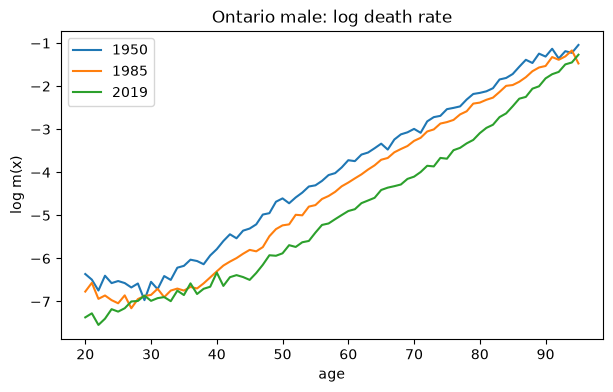

In [31]:
for y in (1950, 1985, 2019):
    plt.plot(AGES, np.log(M["Male"].loc[AGES, y]), label=y)
plt.xlabel("age"); plt.ylabel("log m(x)"); plt.title("Ontario male: log death rate"); plt.legend(); plt.show()

Note that: Below 20, mortality is driven by infant/child causes and its improvement pattern is very different. Above 95 there are few people, so rates are noisy (and sometimes undefined). 

Lee-Carter works best on a block where improvement is broadly smooth. I handle ages 96-110 separately with a Gompertz extension (section 3).

In [32]:
# annual prob of death
# q(x) = m / (1 + 0.5m)
def q_from_m(m): 
    return np.minimum(m / (1 + 0.5 * m), 1.0)
# life expectancy
# p(x) = sum(1 - q(x)) + 0.5
def e_complete(q): 
    return np.cumprod(1 - np.asarray(q)).sum() + 0.5 # q must start at age of interest

print("Observed q(65), male:", {y: round(float(q_from_m(M["Male"].loc[65, y])), 4) for y in (1950, 1985, 2019)})

Observed q(65), male: {1950: 0.035, 1985: 0.0242, 2019: 0.0121}


This is an assumption that for ages 20+, adult mortality is stable enough throughout any single year that deaths average out almost perfectly to the exact midpoint (0.5) 

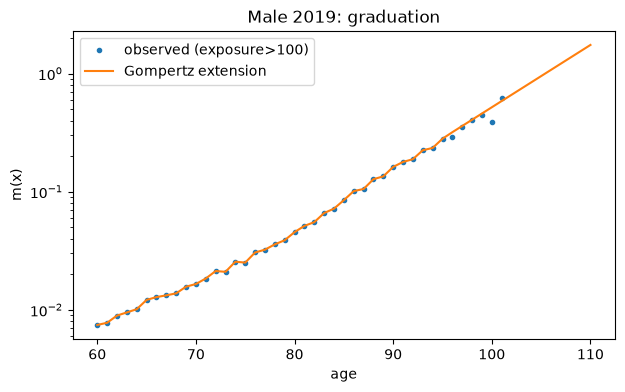

In [33]:
# for old age, Makeham constant is negligible
# Gompertz graduation & extension for old-age
OLD = np.arange(96, 111)

def extend(m95):
    # m95: Series of rates for ages 20..95 -> Series for ages 20..110
    b, a = np.polyfit(np.arange(80, 96), np.log(m95.loc[80:95]), 1)
    return pd.concat([m95, pd.Series(np.exp(a + b * OLD), index=OLD)])

def qx_full(m95):
    q = q_from_m(extend(m95))
    q.iloc[-1] = 1.0
    return q

# visual check: male 2019, observed vs Gompertz
obs = M["Male"][2019]; ok = (E["Male"][2019] > 100)
ext = extend(obs.loc[AGES])
plt.semilogy(obs[ok].loc[60:], "o", ms=3, label="observed (exposure>100)")
plt.semilogy(ext.loc[60:], label="Gompertz extension")
plt.xlabel("age"); plt.ylabel("m(x)"); plt.title("Male 2019: graduation"); plt.legend(); plt.show()

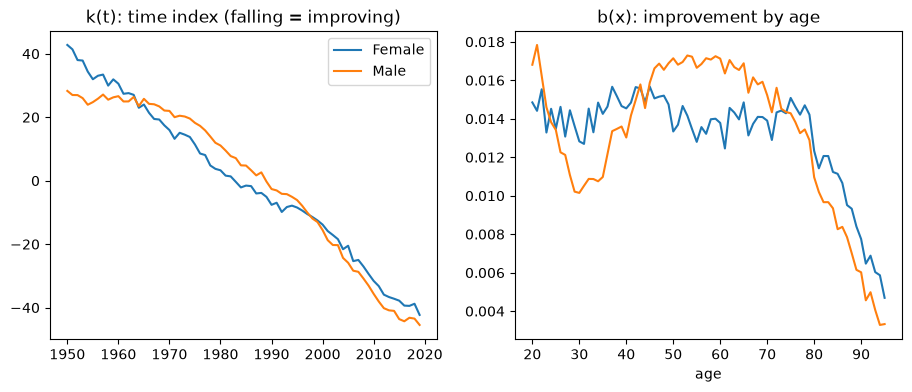

In [34]:
# Lee-Carter
# use log calculation
def fit_lc(logm, sex):
    # age base risk (a) 
    a = logm.mean(axis=1)
    # use matrix math (SVD) to split the remaining data into a time trend and age sensitivity
    U, S, Vt = np.linalg.svd(logm.sub(a, axis=0), full_matrices=False)
    # extract age sensitivity (b) and world progress score (k)
    b = U[:, 0] / U[:, 0].sum() 
    k = S[0] * Vt[0] * U[:, 0].sum()
    b = pd.Series(b, index=logm.index); k = pd.Series(k, index=logm.columns)
    # second stage: choose k(t) so fitted deaths = actual deaths
    for t in k.index:
        Et, Dt = E[sex].loc[logm.index, t], D[sex].loc[logm.index, t].sum()
        k[t] = brentq(lambda z: (Et * np.exp(a + b * z)).sum() - Dt, k[t] - 50, k[t] + 50)
    return a, b, k

def forecast_lc(a, b, k, h):
    # avg drift of progress score
    drift = (k.iloc[-1] - k.iloc[0]) / (len(k) - 1)
    # specific future year list we are predicting
    years = k.index[-1] + np.arange(1, h + 1)
    # project the progress score into those future years
    kf = k.iloc[-1] + drift * np.arange(1, h + 1)
    return pd.DataFrame(np.exp(a.values[:, None] + b.values[:, None] * kf[None, :]), index=a.index, columns=years)

# plot
START = 1950
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for s in SEX:
    a, b, k = fit_lc(np.log(M[s].loc[AGES, START:2019]), s)
    ax[0].plot(k, label=s); ax[1].plot(b, label=s)
ax[0].set_title("k(t): time index (falling = improving)"); ax[1].set_title("b(x): improvement by age")
ax[0].legend(); ax[1].set_xlabel("age"); plt.show()

k(t): Everyone is living longer, but men's progress paused from 1960–1975 (due to smoking/heart attacks) before fast catching up with women.

b(x): Middle-aged men benefited the most from medical progress, while young adult men (accidents/suicide) and the very elderly (biological aging) saw the least improvement.

In [35]:
# backtesting against frozen mortality
# assume 2005 death rates is frozen
TRAIN_END, TEST_END = 2005, 2019

def backtest(sex, start):
    # historical log death rate up to 2005
    lm = np.log(M[sex].loc[AGES, start:TRAIN_END])
    a, b, k = fit_lc(lm, sex)
    # forecast future death rates from 2006 to 2019
    f = forecast_lc(a, b, k, TEST_END - TRAIN_END)
    # real death rates from 2006 to 2019
    act = M[sex].loc[AGES, TRAIN_END + 1:TEST_END]
    frz = pd.DataFrame({y: M[sex].loc[AGES, TRAIN_END] for y in act.columns})
    rows = {}
    for name, p in [(f"Lee-Carter ({start}+)", f), ("Frozen 2005", frz)]:
        err = np.log(p) - np.log(act)
        rows[name] = {"MAE log m (20-95)": err.abs().mean().mean(),
                      "MAE log m (65-95)": err.loc[65:95].abs().mean().mean(),
                      "Bias (65-95)": err.loc[65:95].mean().mean()}
    return pd.DataFrame(rows).T, f, act, frz

# results
out = []
for s in SEX:
    for st in (1921, 1950):
        t, *_ = backtest(s, st); t.insert(0, "Sex", s); out.append(t)
res = pd.concat(out)
res = res.reset_index().rename(columns={"index": "Model"})
res = res[res["Model"].str.startswith("Lee") | ~res.duplicated(["Model", "Sex"])]
res = res.sort_values(["Sex", "Model"]).set_index("Model")
res

,Sex,MAE log m (20-95),MAE log m (65-95),Bias (65-95)
Model,,,,
Frozen 2005,Female,0.1889,0.1669,0.1663
Lee-Carter (1921+),Female,0.2359,0.0929,0.0906
Lee-Carter (1950+),Female,0.1258,0.0727,0.0689
Frozen 2005,Male,0.1527,0.1676,0.1639
Lee-Carter (1921+),Male,0.2629,0.1416,0.1360
Lee-Carter (1950+),Male,0.1597,0.1181,0.1135


- Lee-Carter (1950+) easily beats the frozen benchmark for seniors, cutting prediction errors by **half** for women and **one-third** for men.

- The model fails for younger men because it assumes their health will keep improving, failing to predict real-world setbacks like the opioid crisis.

- Using too much history hurts accuracy, because old infectious disease data from 1921 ruins modern trend predictions, making 1950 the better start year.

- Both models are overly pessimistic about lifespans, meaning real-world populations consistently lived longer than the code predicted.

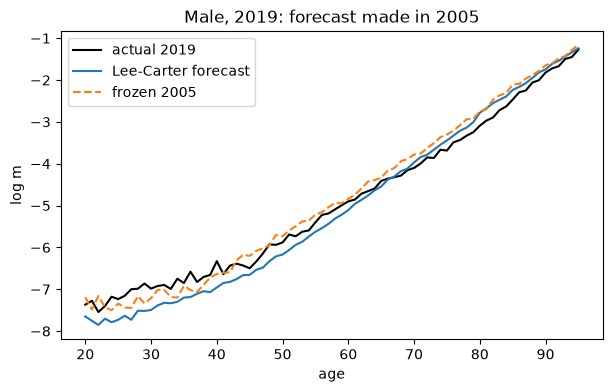

In [36]:
# visual
t, f, act, frz = backtest("Male", START)
plt.plot(AGES, np.log(act[2019]), "k", label="actual 2019")
plt.plot(AGES, np.log(f[2019]), label="Lee-Carter forecast")
plt.plot(AGES, np.log(frz[2019]), "--", label="frozen 2005")
plt.xlabel("age"); plt.ylabel("log m"); plt.title("Male, 2019: forecast made in 2005"); plt.legend(); plt.show()

**Life expectancy at 65 in 2019**, the single number that matters most for annuities: from the actual rates (with Gompertz tail), from the Lee-Carter forecast, and from frozen 2005.

In [37]:
rows = []
for s in SEX:
    _, f, act, frz = backtest(s, START)
    rows.append({"Sex": s,
                 "Actual 2019": e_complete(qx_full(act[2019]).loc[65:]),
                 "Lee-Carter": e_complete(qx_full(f[2019]).loc[65:]),
                 "Frozen 2005": e_complete(qx_full(frz[2019]).loc[65:])})
pd.DataFrame(rows).set_index("Sex")

,Actual 2019,Lee-Carter,Frozen 2005
Sex,,,
Female,22.6526,22.0539,20.7160
Male,19.8208,18.6676,17.7807


In [38]:
# pricing
# assume 2019 death rates is froxen for all future years
FIRST, H = 2020, 50

def projected_q(sex, start=START):
    # historical log death rate up to 2019
    lm = np.log(M[sex].loc[AGES, start:2019])
    a, b, k = fit_lc(lm, sex)
    # forecast future log death rates for 50 years
    f = forecast_lc(a, b, k, H)
    # convert to death prob
    lc = pd.DataFrame({y: qx_full(f[y]) for y in f.columns})
    q19 = qx_full(M[sex].loc[AGES, 2019])
    frz = pd.DataFrame({y: q19 for y in f.columns})
    return lc, frz

# calculate retirement annuity cost
# discount factor (v), survival chance (p), and price (pv)
def annuity_due(q, age, i, T=46):
    v, p, pv = 1 / (1 + i), 1.0, 0.0
    for j in range(T):
        pv += p * v ** j # add discounted value of this year's $1 payout
        p *= 1 - q.loc[age + j, FIRST + j]
    return pv

# calculate life insurance costs
# discount factor (v), survival chance (p), and price (pv)
def term_ins(q, age, n, i):
    v, p, pv = 1 / (1 + i), 1.0, 0.0
    for j in range(n):
        qq = q.loc[age + j, FIRST + j]
        pv += p * qq * v ** (j + 1) # add discounted cost of a possible $1 death payout
        p *= 1 - qq
    return pv

# results
rows = []
for s in SEX:
    lc, frz = projected_q(s)
    # price the retirement annuity at 2%, 3%, 4% interest rates
    for i in (0.02, 0.03, 0.04):
        fa, la = annuity_due(frz, 65, i), annuity_due(lc, 65, i)
        rows.append({"Sex": s, "Product": "Annuity-due 65", "i": i, "Frozen": fa, "Lee-Carter": la, "Change %": 100 * (la / fa - 1)})
    # price the 20-year life insurance policy at a flat 3% interest rate
    ft, lt = term_ins(frz, 45, 20, 0.03), term_ins(lc, 45, 20, 0.03)
    rows.append({"Sex": s, "Product": "20y term 45 (per $1)", "i": 0.03, "Frozen": ft, "Lee-Carter": lt, "Change %": 100 * (lt / ft - 1)})
price = pd.DataFrame(rows)
price

,Sex,Product,i,Frozen,Lee-Carter,Change %
0,Female,Annuity-due 65,0.0200,18.2639,19.1367,4.7788
1,Female,Annuity-due 65,0.0300,16.4138,17.1064,4.2193
2,Female,Annuity-due 65,0.0400,14.8570,15.4105,3.7255
3,Female,20y term 45 (per $1),0.0300,0.0400,0.0314,-21.3552
4,Male,Annuity-due 65,0.0200,16.3870,16.9139,3.2152
5,Male,Annuity-due 65,0.0300,14.8673,15.3034,2.9335
6,Male,Annuity-due 65,0.0400,13.5727,13.9365,2.6804
7,Male,20y term 45 (per $1),0.0300,0.0648,0.0457,-29.5442


- Annuities get more expensive **(+3% to +5%)** because people live longer and collect more payouts, meaning companies that use frozen data will run out of money.

- Term life insurance gets drastically cheaper (**-21%** for women, **-30%** for men) because fewer people die during the policy, meaning frozen data massively overcharges customers.

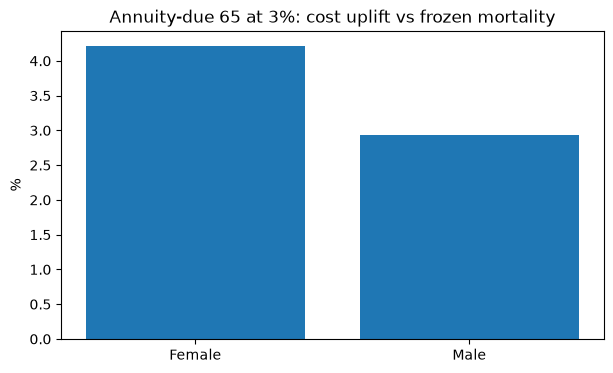

In [39]:
x = price[(price.Product == "Annuity-due 65") & (price.i == 0.03)]
plt.bar(x.Sex, x["Change %"]); plt.ylabel("%"); plt.title("Annuity-due 65 at 3%: cost uplift vs frozen mortality"); plt.show()

In [40]:
# COVID-19: excess mortality
rows = []
for s in SEX:
    a, b, k = fit_lc(np.log(M[s].loc[AGES, START:2019]), s)
    f = forecast_lc(a, b, k, 3)
    for y in (2020, 2021, 2022):
        exp_d = (f[y] * E[s].loc[AGES, y]).sum()
        act_d = D[s].loc[AGES, y].sum()
        rows.append({"Sex": s, "Year": y, "Actual": act_d, "Expected": exp_d,
                     "Excess": act_d - exp_d, "Excess %": 100 * (act_d / exp_d - 1)})
pd.DataFrame(rows)

,Sex,Year,Actual,Expected,Excess,Excess %
0,Female,2020,"50,319.0000","47,361.6592","2,957.3408",6.2442
1,Female,2021,"50,424.0000","47,711.1117","2,712.8883",5.6861
2,Female,2022,"53,965.0000","48,149.3587","5,815.6413",12.0783
3,Male,2020,"57,314.0000","53,750.0456","3,563.9544",6.6306
4,Male,2021,"58,881.0000","54,719.7843","4,161.2157",7.6046
5,Male,2022,"62,278.0000","55,685.3276","6,592.6724",11.8392


- COVID-19 caused massive excess deaths, pushing actual deaths **6% to 7%** higher than expected in 2020–2021, and spiking to **12%** higher in 2022.

- The 2022 spike **(~6,000 extra deaths per sex)** was driven by the Omicron wave, delayed healthcare during the pandemic, and underlying system strains.


In [41]:
# time-series forecasting model
fits, rows = {}, []
for s in SEX:
    a, b, k = fit_lc(np.log(M[s].loc[AGES, START:2019]), s)
    k = pd.Series(k.values.astype(float), index=pd.RangeIndex(len(k)))
    # manual baseline drift using first and last year
    hand = (k.iloc[-1] - k.iloc[0]) / (len(k) - 1)
    # setting (p, d, q)
    # auto-regressive order (p), interated order (d), moving avg order (q)
    for order in [(0, 1, 0), (1, 1, 0), (0, 1, 1)]:
        r = ARIMA(k, order=order, trend="t").fit()
        rows.append({"Sex": s, "Order": order, "AIC": r.aic, "Drift (statsmodels)": r.params.iloc[0],
                     "Drift (by hand)": hand, "Sigma": np.sqrt(r.params["sigma2"])})
        fits[(s, order)] = r
    fits[s] = (a, b, k)
pd.DataFrame(rows).round(3)

,Sex,Order,AIC,Drift (statsmodels),Drift (by hand),Sigma
0,Female,"(0, 1, 0)",254.0920,-1.2330,-1.2330,1.4820
1,Female,"(1, 1, 0)",245.9050,-1.2230,-1.2330,1.3750
2,Female,"(0, 1, 1)",246.2930,-1.2210,-1.2330,1.3790
3,Male,"(0, 1, 0)",228.9340,-1.0690,-1.0690,1.2350
4,Male,"(1, 1, 0)",230.9330,-1.0690,-1.0690,1.2350
5,Male,"(0, 1, 1)",230.9340,-1.0690,-1.0690,1.2350


- Females win with (1, 1, 0): This setup hits the lowest quality score (245.91) and lowest noise, proving women's trends have short-term momentum.

- Males win with (0, 1, 0): This basic random walk has the lowest score (228.93), adding extra complexity for men doesn't help at all.

- Drift math is identical: The software's calculated trend speed perfectly matches our simple manual calculations across the board.

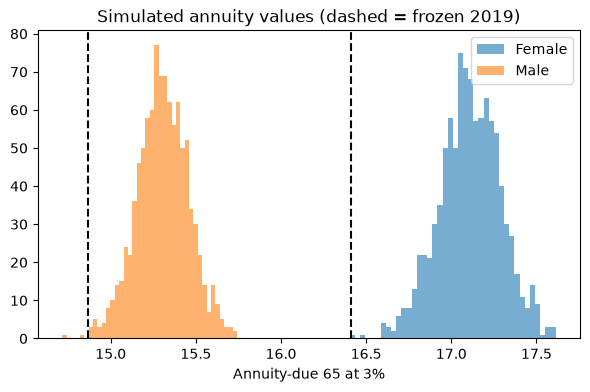

,Frozen,5%,Median,95%
Female,16.4140,16.8030,17.1090,17.3970
Male,14.8670,15.0520,15.3050,15.5450


In [42]:
# Monte Carlo to measure financial risk
N, i = 1000, 0.03
summ = {}
fig, ax = plt.subplots(figsize=(7, 4))
for s in SEX:
    a, b, k = fits[s]
    sims = np.asarray(fits[(s, (0, 1, 0))].simulate(nsimulations=H, repetitions=N, anchor="end", rng=np.random.default_rng(1))).reshape(H, N)
    vals = []
    for j in range(N):
        f = pd.DataFrame(np.exp(a.values[:, None] + b.values[:, None] * sims[:, j][None, :]),
                         index=a.index, columns=FIRST + np.arange(H))
        vals.append(annuity_due(pd.DataFrame({y: qx_full(f[y]) for y in f.columns}), 65, i))
    vals = np.array(vals)
    q19 = qx_full(M[s].loc[AGES, 2019])
    frozen = annuity_due(pd.DataFrame({y: q19 for y in range(FIRST, FIRST + H)}), 65, i)
    summ[s] = {"Frozen": frozen, "5%": np.percentile(vals, 5), "Median": np.median(vals), "95%": np.percentile(vals, 95)}
    ax.hist(vals, bins=40, alpha=.6, label=s); ax.axvline(frozen, ls="--", color="k")
ax.set_xlabel("Annuity-due 65 at 3%"); ax.set_title("Simulated annuity values (dashed = frozen 2019)"); ax.legend(); plt.show()
pd.DataFrame(summ).T.round(3)

The female curve is shifted much further to the right than the male curve, showing that women require significantly more backup cash capital because they live longer.

## Several limitations

- The model uses general population data, ignoring that wealthier insurance buyers live longer, meaning an insurance company would under-reserve for annuities.

- The projection assumes medical progress moves at a single, unchanging speed forever instead of naturally slowing down.

- It projects a single "best guess" line instead of calculating a safe range of possibilities to determine backup cash capital.
